# SLIDE-0235 — what `mxdata sample` built, and what the networks see

`mxdata sample -c configs/dataset.yaml` turns every slide under `$MXDATA_ROOT` into one dataset (`$MXDATA_ROOT/dataset/`):
a labeled grid inside the annotated regions and an unlabeled grid over the rest of the tissue, every marker stored for every
patch. KODIAK pretrains on all of it (labels never read); the segmenters open only the DAPI and LAP2 files of the labeled
patches — the two channels the reference boundaries were drawn from; the analysis reads the other markers of the same patches.

The labeled grid is 256² patches at stride 192, so every border cell is whole in some patch and each patch *owns* the cells
whose centroid falls in its stride core; the unlabeled grid is stride 128, gated by an Otsu tissue mask and never touching a
region. Every patch is a folder named by where it sits, with one image per marker and, when labeled, the complete instance
mask (`mask.png`, every HALO cell), the confirmed mask (`mask_true.png`, the expert's *wrong* cells removed) and its cell
table (`cells.csv`). This notebook looks at **SLIDE-0235** and reads nothing but the dataset and one region of the slide.

| section | question |
|---|---|
| 1 | where did the patches come from — regions, splits, the tissue gate, what was rejected and why |
| 2 | the labeled grid: overlap, owned cores, border cells |
| 3 | what the tables say: cells per patch, cell size, the expert's flags |
| 4 | one patch folder, browsed marker by marker |
| 5 | the stored normalization: what [0, 1] means per marker |
| 6 | what the networks see: the segmenter input, the pretraining draws, the multi-crop views |
| 7 | what the segmenters train on: DAPI + LAP2 of a labeled patch, the complete and the confirmed mask |

In [1]:
# pick up edits to src/ without restarting the kernel
%load_ext autoreload
%autoreload 2
import json, os
from pathlib import Path
import cv2, numpy as np, pandas as pd, tifffile, yaml
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from mxdata import DEFAULT_DATASET, ingest, load_config, load_regions
from mxdata.data.composite import render_channels, scaled
from mxdata.io import Box
from mxdata.pipeline.sample import TEXT_COLUMNS, read_dataset_json
from mxdata.pipeline.stats import NormStats
from mxdata.pipeline.tissue import TissueGate
from mxseg.analysis import load_panel

plt.rcParams.update({
    "figure.dpi": 135, "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "font.size": 8.5, "axes.titlesize": 9, "axes.titleweight": "bold", "axes.labelsize": 8.5,
    "xtick.labelsize": 8, "ytick.labelsize": 8, "legend.fontsize": 8,
    "axes.linewidth": 0.7, "xtick.major.width": 0.7, "ytick.major.width": 0.7,
    "xtick.major.size": 2.6, "ytick.major.size": 2.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": False,
    "legend.frameon": False, "figure.facecolor": "white", "savefig.facecolor": "white",
    "axes.titlelocation": "left",
})
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATASET = Path(os.environ.get("MXDATA_DATASET", DEFAULT_DATASET))

# ---- edit here ---------------------------------------------------------------------------------------------------------
SLIDE = "SLIDE-0235"
REGION = 15                        # the region drawn in section 2 (a reviewed held-out region)
# ------------------------------------------------------------------------------------------------------------------------

INK, MUTED, GRID = "#1A1C1F", "#6B7075", "#E4E6E9"
SPLIT_COLOR = {"train": "#FFFFFF", "val": "#FFB000", "test": "#35D6FF"}
BAR_COLOR = {"train": "#9AA3AD", "val": "#FFB000", "test": "#35D6FF"}
FLAG_COLOR = {"OK": "#1BAF7A", "WRONG": "#EDA100", "UNKNOWN": "#9AA3AD", "NO_QC_ROW": "#E34948"}
FLAG_NAME = {"OK": "confirmed", "WRONG": "flagged wrong", "UNKNOWN": "no review", "NO_QC_ROW": "no QC row"}
CHIP = dict(boxstyle="round,pad=0.22", fc="black", ec="none", alpha=0.6)

def panel(ax, letter, dx=-0.04, dy=1.04):
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=11.5, fontweight="bold", va="bottom", ha="right", color=INK)

def chip(ax, text):
    ax.text(0.02, 0.975, text, transform=ax.transAxes, fontsize=7.2, fontweight="bold", color="white", va="top", bbox=CHIP)

def ygrid(ax):
    ax.grid(axis="y", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def xgrid(ax):
    ax.grid(axis="x", color=GRID, lw=0.7, zorder=0); ax.set_axisbelow(True)

def barh_clean(ax):
    ax.spines["left"].set_visible(False); ax.tick_params(axis="y", length=0)

def display(x, gain=1.0, gamma=0.8):
    return np.clip(x * gain, 0, 1) ** gamma

def hexrgb(h):
    return [int(h[i:i + 2], 16) / 255 for i in (1, 3, 5)]

def paint(gray, labels, cells, core=None):
    """The mask over a gray image: owned cells green, cells owned by a neighbor gray, flagged cells amber."""
    rgb = np.repeat(gray[..., None], 3, -1) * 0.75
    lut = np.zeros((int(labels.max()) + 1, 3), np.float32)
    for row in cells.itertuples():
        lut[row.local_id] = hexrgb(FLAG_COLOR["WRONG"] if row.flag == "WRONG" else ("#1BAF7A" if row.owned else "#9AA3AD"))
    sel = labels > 0
    rgb[sel] = 0.35 * rgb[sel] + 0.65 * lut[labels[sel]]
    return rgb

cfg = load_config(REPO / "configs" / "dataset.yaml")
panelcfg = load_panel(REPO / "configs" / "panel.yaml")
info = read_dataset_json(DATASET)
MARKERS = list(info["markers"])
pt = pd.read_csv(DATASET / "patches.csv", dtype={c: str for c in TEXT_COLUMNS})
inst = pd.read_csv(DATASET / "instances.csv")
slides = pd.read_csv(DATASET / "slides.csv")
assert SLIDE in info["slides"], f"{SLIDE} is not in {DATASET}: {info['slides']}"
stats = NormStats.load(DATASET / SLIDE / "stats.json")
NORMS = {m: (stats.lo[m], stats.hi[m]) for m in MARKERS}
paths, mx, _ = ingest(SLIDE, None)
PX_UM = float(mx.pixel_size_um or 0.325)
regions = {r.region_id: r for r in load_regions(paths, None, cfg.min_area_px)}
mine = pt[pt.slide == SLIDE]                                                       # this slide's windows, kept or not
lab = mine[(mine.kind == "labeled") & mine.kept.astype(bool)]                      # its labeled patches
split_of = lab.groupby("region_id").split.first().to_dict()
G = info["geometry"]
print(f"{DATASET.name}: {info['counts']['n_kept']} kept patches of {info['counts']['n_windows']} windows on {info['slides']} — "
      f"{info['counts']['n_labeled']} labeled + {info['counts']['n_unlabeled']} unlabeled | patch {G['size']}², labeled stride {G['stride']}, "
      f"unlabeled stride {G['unlabeled_stride']} | markers {MARKERS}")
print(pt[pt.kept.astype(bool)].groupby(["slide", "kind", "split"]).size().to_string())
print(f"\n{SLIDE}: {len(lab)} labeled patches over {len(regions)} regions ({sum(r.has_qc for r in regions.values())} reviewed), "
      f"{int(((mine.kind == 'unlabeled') & mine.kept.astype(bool)).sum())} unlabeled | splits: "
      + ", ".join(f"{sp} = R{sorted(lab[lab.split == sp].region_id.unique().tolist())}" for sp in ("train", "val", "test")))

dataset: 9540 kept patches of 33986 windows on ['SLIDE-0233', 'SLIDE-0235', 'SLIDE-0236'] — 959 labeled + 8581 unlabeled | patch 256², labeled stride 192, unlabeled stride 128 | markers ['DAPI', 'LAP2', 'PanCK', 'CD45', 'CD3', 'CD4', 'CD8', 'FOXP3', 'uPAR']
slide       kind       split
SLIDE-0233  labeled    test       72
SLIDE-0235  labeled    train     550
                       val        78
            unlabeled  train    4478
SLIDE-0236  labeled    test      259
            unlabeled  test     4103

SLIDE-0235: 628 labeled patches over 16 regions (16 reviewed), 4478 unlabeled | splits: train = R[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 16], val = R[14, 15], test = R[]


## 1. Where the patches come from

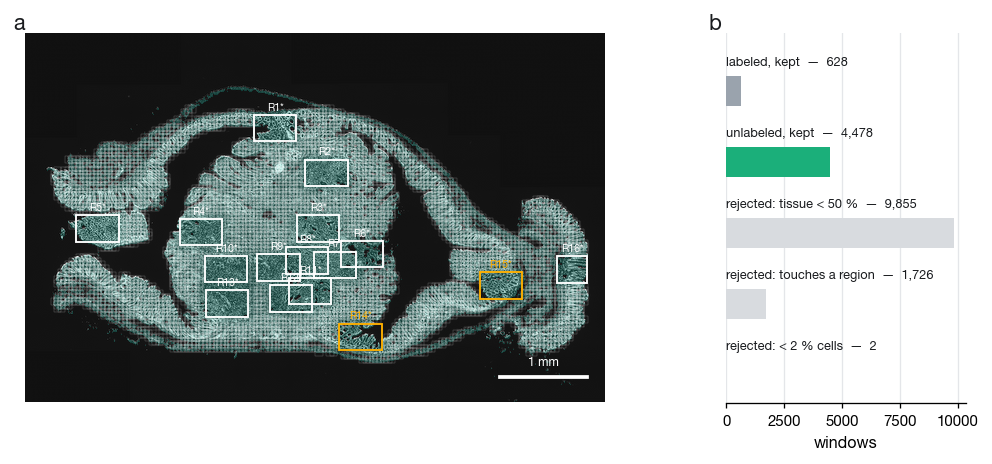

tissue gate: Otsu on a 2048-px DAPI thumbnail, threshold 361, 36 % of the slide is tissue | a window is kept when >= 50 % of it is tissue


In [2]:
thumb, ds = mx.thumbnail(max_dim=2000, markers=["DAPI"])
dapi = np.clip(thumb[0].astype(np.float32) / np.percentile(thumb[0], 99.5), 0, 1) ** 0.7
gate = TissueGate.from_slide(mx, cfg.patches.tissue_marker, cfg.patches.tissue_max_dim)
H, W = dapi.shape
kept_unl = mine[(mine.kind == "unlabeled") & mine.kept.astype(bool)]

fig = plt.figure(figsize=(7.6, 3.3))
gs = fig.add_gridspec(1, 2, width_ratios=[3.4, 1.15], wspace=0.12, left=0.01, right=0.99, top=0.95, bottom=0.12)
a = fig.add_subplot(gs[0])
a.imshow(dapi, cmap="gray", vmin=0, vmax=1, interpolation="lanczos")
mask_rgba = np.zeros((*gate.mask.shape, 4), np.float32); mask_rgba[gate.mask.astype(bool)] = [0.1, 0.85, 0.75, 0.22]
a.imshow(mask_rgba, extent=(0, gate.mask.shape[1] * gate.downsample / ds, gate.mask.shape[0] * gate.downsample / ds, 0), interpolation="nearest")
for r in kept_unl.itertuples():                                                   # every kept unlabeled window (stride 128: they overlap)
    a.add_patch(Rectangle((r.x0 / ds, r.y0 / ds), (r.x1 - r.x0) / ds, (r.y1 - r.y0) / ds, fill=False, ec="white", lw=0.25, alpha=0.35))
for rid, r in regions.items():
    b, sp = r.box, split_of.get(rid, "train")
    a.add_patch(Rectangle((b.x0 / ds, b.y0 / ds), b.width / ds, b.height / ds, fill=False, ec=SPLIT_COLOR[sp], lw=1.0))
    a.text(b.x0 / ds + b.width / ds / 2, b.y0 / ds - 0.008 * H, f"R{rid}{'*' if r.has_qc else ''}", color=SPLIT_COLOR[sp], fontsize=5.6,
           fontweight="bold", ha="center", va="bottom")
a.set_xlim(0, W); a.set_ylim(H, 0); a.set_axis_off()
L = 1000 / (PX_UM * ds); a.plot([W * 0.97 - L, W * 0.97], [H * 0.93] * 2, color="white", lw=2); a.text(W * 0.97 - L / 2, H * 0.90, "1 mm", color="white", ha="center", fontsize=6.5)
panel(a, "a", dx=0.0, dy=1.0)
b_ = fig.add_subplot(gs[1])
outcomes = [("labeled, kept", len(lab), BAR_COLOR["train"]),
            ("unlabeled, kept", len(kept_unl), "#1BAF7A"),
            ("rejected: tissue < %d %%" % round(100 * cfg.patches.min_tissue), int(mine.reject_reason.fillna("").str.startswith("tissue<").sum()), "#D8DBDF"),
            ("rejected: touches a region", int((mine.reject_reason == "fov_overlap").sum()), "#D8DBDF"),
            ("rejected: < %d %% cells" % round(100 * cfg.patches.min_fg), int(mine.reject_reason.fillna("").str.startswith("fg<").sum()), "#D8DBDF")]
y = np.arange(len(outcomes))[::-1]
b_.barh(y - 0.12, [o[1] for o in outcomes], color=[o[2] for o in outcomes], height=0.42, zorder=3)
for yi, (name, n, _) in zip(y, outcomes):
    b_.text(0, yi + 0.2, f"{name}  —  {n:,}", va="bottom", ha="left", fontsize=6.8, color=INK)
b_.set_yticks([]); b_.set_xlabel("windows"); b_.set_xlim(0, max(o[1] for o in outcomes) * 1.05)
b_.set_ylim(-0.5, len(outcomes) - 0.3)
xgrid(b_); barh_clean(b_)
panel(b_, "b", dx=-0.02, dy=1.0)
plt.show()
print(f"tissue gate: Otsu on a {cfg.patches.tissue_max_dim}-px DAPI thumbnail, threshold {gate.info.get('threshold_intensity', 0):.0f}, "
      f"{100 * gate.info.get('tissue_fraction', 0):.0f} % of the slide is tissue | a window is kept when >= {100 * cfg.patches.min_tissue:.0f} % of it is tissue")

**Figure 1 — Where the patches come from.** (a) The slide (DAPI) with the tissue gate (teal: the Otsu mask on a coarse DAPI
thumbnail), the annotated regions boxed by split (white training, amber validation, cyan test; \* = reviewed by the
expert, which is now every region of this slide — the protocol is leave-slide-out: SLIDE-0235 trains and validates, SLIDE-0236 is the test slide), and every kept unlabeled window as a faint square: a half-overlapping grid (stride 128) over the tissue, never
touching a region — the pretraining stream. (b) What became of every window of the two grids on this slide: kept labeled
(inside the regions), kept unlabeled, and the rejections with their reason. `patches.csv` keeps the rejected rows too, so
any threshold can be re-checked from the table.

## 2. The labeled grid: overlap, owned cores, border cells

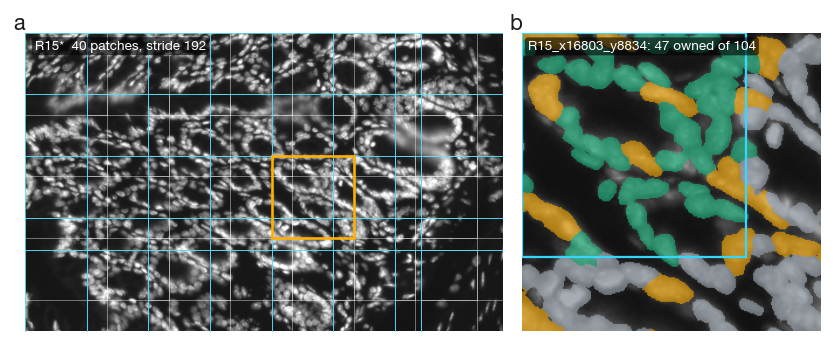

region R15: 40 windows, 40 kept; patch SLIDE-0235_R15_x16803_y8834: 104 cells, 47 owned by its core, 35 touching the border, 18 flagged wrong


In [3]:
r = regions[REGION]
reg_dapi = mx.read_region(r.box, ["DAPI"], 0)[0].astype(np.float32)
reg_dapi = np.clip(reg_dapi / np.percentile(reg_dapi, 99.5), 0, 1) ** 0.7
win = mine[(mine.kind == "labeled") & (mine.region_id == REGION)]
kept = win[win.kept.astype(bool)]
pick = kept.iloc[len(kept) // 2]                                                  # one patch, drawn in (b)
pk = pd.read_csv(DATASET / pick.image / "cells.csv")

fig = plt.figure(figsize=(7.6, 3.3))
gs = fig.add_gridspec(1, 2, width_ratios=[1.6, 1], wspace=0.05)
a = fig.add_subplot(gs[0])
a.imshow(reg_dapi, cmap="gray", vmin=0, vmax=1)
for w in win.itertuples():
    a.add_patch(Rectangle((w.x0 - r.box.x0, w.y0 - r.box.y0), w.x1 - w.x0, w.y1 - w.y0, fill=False, ec="white" if w.kept else "#E34948", lw=0.35, alpha=0.6))
    a.add_patch(Rectangle((w.core_x0 - r.box.x0, w.core_y0 - r.box.y0), w.core_x1 - w.core_x0, w.core_y1 - w.core_y0, fill=False, ec="#35D6FF", lw=0.5, alpha=0.7))
a.add_patch(Rectangle((pick.x0 - r.box.x0, pick.y0 - r.box.y0), pick.x1 - pick.x0, pick.y1 - pick.y0, fill=False, ec="#FFB000", lw=1.4))
a.set_axis_off(); chip(a, f"R{REGION}{'*' if r.has_qc else ''}  {len(kept)} patches, stride {G['stride']}")
panel(a, "a", dx=0.0, dy=1.0)
b_ = fig.add_subplot(gs[1])
gray = tifffile.imread(DATASET / pick.image / "DAPI.tif").astype(np.float32)
gray = np.clip(gray / np.percentile(gray, 99.5), 0, 1) ** 0.7
labels = cv2.imread(str(DATASET / pick["mask"]), -1).astype(np.int32)
b_.imshow(paint(gray, labels, pk))
b_.add_patch(Rectangle((pick.core_x0 - pick.x0, pick.core_y0 - pick.y0), pick.core_x1 - pick.core_x0, pick.core_y1 - pick.core_y0, fill=False, ec="#35D6FF", lw=1.2))
b_.set_axis_off(); chip(b_, f"{pick.key.split('_', 1)[1]}: {int(pick.n_owned)} owned of {int(pick.n_instances)}")
panel(b_, "b", dx=0.0, dy=1.0)
plt.show()
print(f"region R{REGION}: {len(win)} windows, {len(kept)} kept; patch {pick.key}: {int(pick.n_instances)} cells, {int(pick.n_owned)} owned by its core, "
      f"{int(pick.n_border)} touching the border, {int(pick.n_wrong)} flagged wrong")

**Figure 2 — The labeled grid.** (a) One reviewed held-out region with every labeled window (white; red = rejected for too few
cell pixels) and its owned core (cyan): windows overlap by 64 px so that every cell at a window border is whole in a
neighbor, and each cell is *owned* — counted in training metrics and patch-level evaluation — by exactly one window, the
one whose stride core holds its centroid. (b) The window highlighted in amber, as stored: its mask over DAPI with owned
cells green, cells owned by a neighbor gray, and expert-flagged cells amber; the core in cyan. Region-level evaluation
does not need ownership: it scores whole regions.

## 3. What the tables say

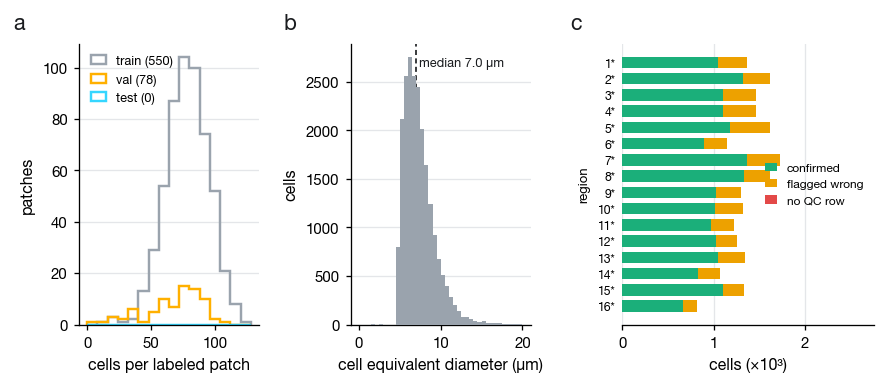

21,657 cells owned once across 628 labeled patches of SLIDE-0235: 16,985 confirmed, 4,668 flagged wrong (22 % of the reviewed cells), 4 not reviewed


In [4]:
owned = inst[(inst.slide == SLIDE) & inst.owned.astype(bool)]                     # each cell of this slide once, through the patch that owns it
owned = owned.assign(split=owned.patch_key.map(lab.set_index("key").split), diam_um=2 * np.sqrt(owned.area_px / np.pi) * PX_UM)
fig = plt.figure(figsize=(7.6, 2.7))
gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.4], wspace=0.45)
a = fig.add_subplot(gs[0])
for sp in ("train", "val", "test"):
    a.hist(lab[lab.split == sp].n_instances, bins=np.arange(0, lab.n_instances.max() + 8, 8), histtype="step", lw=1.3, color=BAR_COLOR[sp], label=f"{sp} ({(lab.split == sp).sum()})")
a.set_xlabel("cells per labeled patch"); a.set_ylabel("patches"); a.legend(fontsize=6.8, handlelength=1.2); ygrid(a)
panel(a, "a", dx=-0.3)
b_ = fig.add_subplot(gs[1])
b_.hist(owned.diam_um, bins=np.linspace(0, 20, 41), color="#9AA3AD", zorder=3)
med = owned.diam_um.median(); b_.axvline(med, color=INK, lw=0.9, ls=(0, (3, 2))); b_.text(med + 0.3, b_.get_ylim()[1] * 0.92, f"median {med:.1f} µm", fontsize=6.8, color=INK)
b_.set_xlabel("cell equivalent diameter (µm)"); b_.set_ylabel("cells"); ygrid(b_)
panel(b_, "b", dx=-0.3)
c = fig.add_subplot(gs[2])
flags = owned.groupby(["region_id", "flag"]).size().unstack(fill_value=0).reindex(columns=[f for f in FLAG_COLOR if f in owned.flag.unique()], fill_value=0).sort_index()
y = np.arange(len(flags))[::-1]; left = np.zeros(len(flags))
for f in flags.columns:
    c.barh(y, flags[f] / 1000, left=left / 1000, color=FLAG_COLOR[f], height=0.7, zorder=3, label=FLAG_NAME[f])
    left += flags[f].values
c.set_yticks(y, [f"{rid}{'*' if regions[rid].has_qc else ''}" for rid in flags.index], fontsize=6.5); c.set_xlabel("cells (×10³)")
c.set_xlim(0, flags.sum(1).max() / 1000 * 1.6); c.set_ylabel("region", fontsize=7)
c.legend(fontsize=6.4, loc="center right", handlelength=1.0); xgrid(c); barh_clean(c)
panel(c, "c", dx=-0.16)
plt.show()
reviewed = owned[owned.flag.isin(["OK", "WRONG"])]
print(f"{len(owned):,} cells owned once across {len(lab)} labeled patches of {SLIDE}: {(owned.flag == 'OK').sum():,} confirmed, "
      f"{(owned.flag == 'WRONG').sum():,} flagged wrong ({100 * (reviewed.flag == 'WRONG').mean():.0f} % of the reviewed cells), "
      f"{(~owned.flag.isin(['OK', 'WRONG'])).sum():,} not reviewed")

**Figure 3 — The tables.** (a) Cells per labeled patch by split (`patches.csv`, `n_instances`). (b) Cell size from
`instances.csv`, each cell counted once through the patch that owns it: HALO cell objects are DAPI-anchored with a small
cytoplasmic margin, hence the ~7–8 µm median. (c) The expert's review per region, from HALO's QC table: a blank row is a
confirmed cell, a *Wrong* row is one of HALO's errors. All 16 regions of this slide are reviewed, so every cell is either
confirmed or flagged (a handful of HALO cells have no QC row at all and are kept as drawn). The
flags travel with each patch (`cells.csv`, `instances.csv`) and decide what the segmenters train on (section 7).

## 4. One patch folder, browsed

SLIDE-0235/R06_x11330_y7530/ : CD3.tif  CD4.tif  CD45.tif  CD8.tif  DAPI.tif  FOXP3.tif  LAP2.tif  PanCK.tif  cells.csv  mask.png  mask_true.png  uPAR.tif


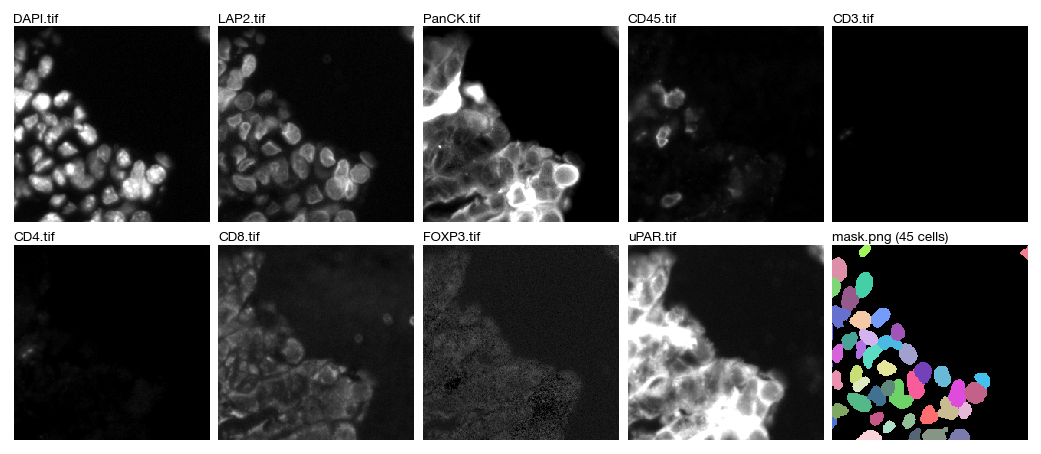

In [5]:
cand = lab[lab.n_wrong > 0]
folder = DATASET / (cand.iloc[len(cand) // 3] if len(cand) else lab.iloc[0]).image
files = sorted(os.listdir(folder))
print(f"{folder.relative_to(DATASET)}/ : " + "  ".join(files))
fig, axes = plt.subplots(2, 5, figsize=(7.6, 3.3))
fig.subplots_adjust(wspace=0.04, hspace=0.12, left=0.005, right=0.995, top=0.94, bottom=0.01)
for ax, m in zip(axes.ravel(), MARKERS):
    x = tifffile.imread(folder / f"{m}.tif")
    ax.imshow(display(scaled(x, *NORMS[m]), gain=1.4), cmap="gray", vmin=0, vmax=1, interpolation="nearest"); ax.set_axis_off()
    ax.set_title(f"{m}.tif", fontsize=7.2, pad=2)
ax = axes.ravel()[-1]
lab_img = cv2.imread(str(folder / "mask.png"), -1).astype(np.int32)
rng = np.random.default_rng(1); cmap = np.vstack([[0, 0, 0], rng.uniform(0.25, 1.0, (int(lab_img.max()), 3))])
ax.imshow(cmap[lab_img], interpolation="nearest"); ax.set_axis_off(); ax.set_title(f"mask.png ({lab_img.max()} cells)", fontsize=7.2, pad=2)
plt.show()

**Figure 4 — One patch folder, as it is on disk.** The nine marker images of one labeled patch (each `uint16` TIFF scaled
by its slide-level window, see section 5) and its `mask.png`, instance ids local to the patch. Next to them sit
`mask_true.png` (the same ids with the flagged cells removed) and `cells.csv` (one row per id: area, centroid, HALO id,
flag, owned, border). The folder name is the patch's identity — region and level-0 coordinates of its top-left corner —
and the tables refer to it by that path.

## 5. The stored normalization

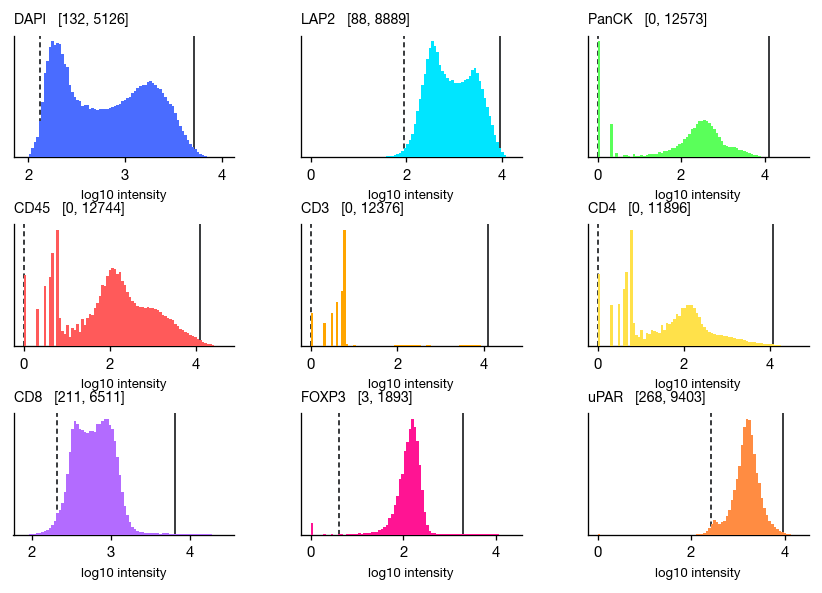

stats.json: percentiles 1.0 / 99.7 of a 2,000,000-pixel sample over the 16 annotated regions of SLIDE-0235


In [6]:
rng = np.random.default_rng(0)
sample = mine[mine.kept.astype(bool)].sample(64, random_state=0)
vals = {m: [] for m in MARKERS}
for r in sample.itertuples():
    for m in MARKERS:
        vals[m].append(tifffile.imread(DATASET / r.image / f"{m}.tif").ravel()[::13])
fig, axes = plt.subplots(3, 3, figsize=(7.6, 4.8))
fig.subplots_adjust(hspace=0.55, wspace=0.3)
for ax, m in zip(axes.ravel(), MARKERS):
    v = np.concatenate(vals[m]).astype(np.float32)
    lo, hi = NORMS[m]
    ax.hist(np.log10(v + 1), bins=80, color=panelcfg.colors.get(m, "#9AA3AD"), zorder=3)
    for q, ls in ((lo, (0, (3, 2))), (hi, "-")):
        ax.axvline(np.log10(q + 1), color=INK, lw=0.9, ls=ls)
    ax.set_title(f"{m}   [{lo:.0f}, {hi:.0f}]", fontsize=7.6); ax.set_yticks([]); ax.set_xlabel("log10 intensity", fontsize=7)
    ygrid(ax)
plt.show()
print(f"stats.json: percentiles {stats.pmin} / {stats.pmax} of a {stats.sample_pixels:,}-pixel sample over the {stats.n_windows} annotated regions of {SLIDE}")

**Figure 5 — What [0, 1] means per marker.** Intensity distributions over 64 random patches, with the stored window
(`stats.json`: dashed = 1st percentile, solid = 99.7th, sampled once over the annotated regions of the slide) that every
network input is scaled with. One window per marker per slide — not per patch, which would make patches incomparable, and
not over the whole slide, where background would set the range — and the same numbers for pretraining, training and
evaluation.

## 6. What the networks see

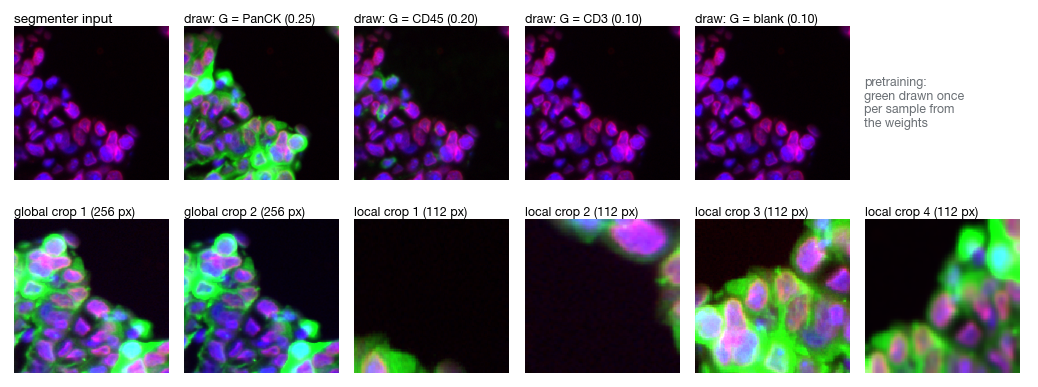

segmenters: R LAP2 · G — · B DAPI | pretraining: R LAP2 · G drawn per sample (PanCK 0.25, CD45 0.20, CD3 0.10, CD4 0.10, CD8 0.10, uPAR 0.10, FOXP3 0.05, blank 0.10) · B DAPI | photometrics: mxif


In [7]:
import torch
from kodiak.transforms import make_transform

ssl = yaml.safe_load((REPO / "configs" / "kodiak_pretrain.yaml").read_text())["data"]
seg = yaml.safe_load((REPO / "configs" / "train_unet.yaml").read_text())["input"]
stack = np.stack([tifffile.imread(folder / f"{m}.tif") for m in MARKERS])
weights = {k: v for k, v in ssl["input"]["green"].items()}
draws = [m for m in ("PanCK", "CD45", "CD3", "blank") if m in weights][:4]
fig, axes = plt.subplots(2, 6, figsize=(7.6, 2.8))
fig.subplots_adjust(wspace=0.04, hspace=0.25, left=0.005, right=0.995, top=0.93, bottom=0.01)
axes[0, 0].imshow(display(render_channels(stack, MARKERS, NORMS, (seg["red"], seg["green"], seg["blue"])), gain=1.6)[..., :].transpose(1, 2, 0))
axes[0, 0].set_title("segmenter input", fontsize=7.2, pad=2)
for ax, g in zip(axes[0, 1:1 + len(draws)], draws):
    ch = (ssl["input"]["red"], None if g == "blank" else g, ssl["input"]["blue"])
    ax.imshow(display(render_channels(stack, MARKERS, NORMS, ch), gain=1.6).transpose(1, 2, 0))
    ax.set_title(f"draw: G = {g} ({weights[g]:.2f})", fontsize=6.6, pad=2)
axes[0, -1].set_axis_off()
axes[0, -1].text(0.02, 0.5, "pretraining:\ngreen drawn once\nper sample from\nthe weights", fontsize=6.6, color=MUTED, va="center", transform=axes[0, -1].transAxes)
tf = make_transform(ssl["augmentation"])
x = torch.from_numpy(render_channels(stack, MARKERS, NORMS, (ssl["input"]["red"], "PanCK", ssl["input"]["blue"])))
torch.manual_seed(0)
views = tf(x)
mean, std = torch.tensor(ssl["augmentation"]["normalize_mean"]).view(3, 1, 1), torch.tensor(ssl["augmentation"]["normalize_std"]).view(3, 1, 1)
for ax, v, name in zip(axes[1], views["global_crops"] + views["local_crops"], ["global crop 1", "global crop 2"] + [f"local crop {i + 1}" for i in range(4)]):
    ax.imshow(display((v * std + mean).clamp(0, 1).numpy(), gain=1.6).transpose(1, 2, 0), interpolation="nearest")
    ax.set_title(f"{name} ({v.shape[-1]} px)", fontsize=6.6, pad=2)
for ax in axes.ravel():
    ax.set_axis_off()
plt.show()
print(f"segmenters: R {seg['red']} · G {seg['green'] or '—'} · B {seg['blue']} | pretraining: R {ssl['input']['red']} · G drawn per sample "
      f"({', '.join(f'{k} {v:.2f}' for k, v in weights.items())}) · B {ssl['input']['blue']} | photometrics: {ssl['augmentation'].get('photometric', 'mxif')}")

**Figure 6 — What the networks see.** Top: the same patch as the segmenters receive it — LAP2 in red and DAPI in blue, the
two channels the reference boundaries were drawn from, and nothing in green — and as KODIAK pretraining receives it, with a
context marker drawn into green once per sample from the configured weights (or left blank). Bottom: the multi-crop views of
one such draw as the pretraining objectives see them — two global crops and four local crops after the MxIF augmentation
(flips, 90° rotations, per-channel gain and gamma, blur; no hue rotation, grayscale or solarization). The green marker is
the same in every crop of a sample, so the cross-view objectives compare views that agree on content.

## 7. What the segmenters train on

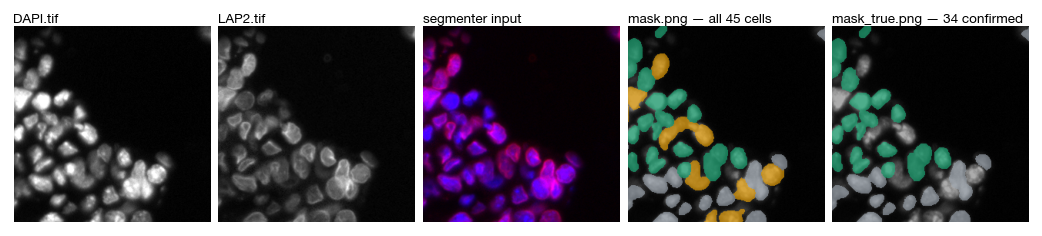

 local_id  nucleus_id  label  flag  area_px           cx          cy  touches_border  owned
        1         323    324    OK    166.5 11372.382353 7538.441176            True   True
        2         324    325    OK    657.5 11597.235294 7542.305882            True  False
        3         336    337    OK    513.0 11337.574713 7566.747126            True   True
        4         352    353 WRONG    565.0 11368.855556 7586.011111           False   True
        5         364    365    OK    400.0 11332.686747 7582.963855            True   True
        6         374    375    OK    509.5 11354.509804 7601.696078           False   True
... 45 rows: 11 flagged wrong (amber), 25 owned by this patch, 15 touching the border
the segmenters open LAP2.tif, DAPI.tif and the mask of the 628 labeled patches of SLIDE-0235 — nothing else in dataset


In [8]:
cells = pd.read_csv(folder / "cells.csv")                                         # the patch of section 4
complete = cv2.imread(str(folder / "mask.png"), -1).astype(np.int32)
true = cv2.imread(str(folder / "mask_true.png"), -1).astype(np.int32)
d, l = (tifffile.imread(folder / f"{m}.tif") for m in ("DAPI", "LAP2"))
gray = display(scaled(d, *NORMS["DAPI"]), gain=1.4)
fig, axes = plt.subplots(1, 5, figsize=(7.6, 1.85))
fig.subplots_adjust(wspace=0.04, left=0.005, right=0.995, top=0.88, bottom=0.01)
axes[0].imshow(gray, cmap="gray", vmin=0, vmax=1); axes[0].set_title("DAPI.tif", fontsize=7.2, pad=2)
axes[1].imshow(display(scaled(l, *NORMS["LAP2"]), gain=1.4), cmap="gray", vmin=0, vmax=1); axes[1].set_title("LAP2.tif", fontsize=7.2, pad=2)
axes[2].imshow(display(render_channels(np.stack([d, l]), ["DAPI", "LAP2"], {m: NORMS[m] for m in ("DAPI", "LAP2")}, (seg["red"], seg["green"], seg["blue"])), gain=1.6).transpose(1, 2, 0))
axes[2].set_title("segmenter input", fontsize=7.2, pad=2)
axes[3].imshow(paint(gray * 0.9, complete, cells)); axes[3].set_title(f"mask.png — all {len(cells)} cells", fontsize=7.2, pad=2)
axes[4].imshow(paint(gray * 0.9, true, cells[cells.flag != "WRONG"])); axes[4].set_title(f"mask_true.png — {len(np.unique(true)) - 1} confirmed", fontsize=7.2, pad=2)
for ax in axes:
    ax.set_axis_off()
plt.show()
print(cells.head(6).to_string(index=False))
print(f"... {len(cells)} rows: {(cells.flag == 'WRONG').sum()} flagged wrong (amber), {int(cells.owned.sum())} owned by this patch, {int(cells.touches_border.sum())} touching the border")
print(f"the segmenters open {seg['red']}.tif, {seg['blue']}.tif and the mask of the {len(lab)} labeled patches of {SLIDE} — nothing else in {DATASET.name}")

**Figure 7 — What the segmenters train on.** The patch of section 4 as the segmenters read it: only the two markers the
reference boundaries were drawn from (DAPI, LAP2), rendered as LAP2 red · green empty · DAPI blue, and its labels — the
complete mask with every HALO cell (flagged cells amber) and the confirmed mask with the flagged cells removed; the
`cells.csv` rows carry the flags and the ownership. Training reads the complete mask with its cell table and puts every
flagged cell into the ignore mask, so neither those cells' boundaries nor the background under them enter the loss —
the models learn from the confirmed cells only. The complete mask exists for inspection: what HALO produced and what
the expert struck out.